# Combine forced-choice and Likert responses in R

Fit one model to rankings and individual item ratings from the same 80 simulated
respondents. Both response types measure the trait `agency`. Only the forced-choice
blocks also measure `stability`.

In a forced-choice block, the model assigns probability to the whole response
pattern. For the GPCM rating items, category $k$ has weight proportional to
$\exp(k a_i\theta_p+\delta_{ik})$, where $a_i$ is the item loading,
$\theta_p$ is the respondent's agency score and $\delta_{ik}$ is the category
intercept. Dividing each weight by the sum gives the category probability.
Using the same trait name in both designs means that both likelihoods use the
same respondent score. See the [Python companion](joint_workflow.ipynb) for a
comparison with separate traits.

## Inspect the two response tables

A forced-choice row records the ranks of the statements in one block. An item
row records one response category. The same `person_id` links the tables.

In [1]:
library(pyfcirt)

example <- load_example("mixed_measurement", model = list(fc = "MGPPM", items = "GPCM"))
head(example$fc$responses, 3)

  person_id block_id response
1      P001       B1  3, 1, 2
2      P002       B1  2, 1, 3
3      P003       B1  1, 2, 3


In [2]:
head(example$items$responses, 3)

  person_id item_id response
1      P001      I1        1
2      P002      I1        3
3      P003      I1        2


## Register both channels

Use MGPPM for B1–B3 and TwoPLRank for B4. The individual items use GPCM for
I1–I3 and 2PL for the binary item I4. The declarations set reference statement
intercepts to zero on the forced-choice side. Passing `agency` in the individual
item design links the ratings to the agency scale already in the block design.

In [3]:
fc <- reticulate::import("pyfcirt", convert = FALSE)

m <- model()
m$add_fc(example$fc$design, example$fc$responses, format = example$fc$format,
         response_format = example$fc$response_format,
         model = fc$MGPPM(reference_statements = list("A", "D", "G")),
         blocks = list(B4 = list(model = fc$TwoPLRank(reference_statements = list("J")))))

m$add_items("[traits]
agency ~ I1 I2 I3 I4", example$items$responses,
            format = example$items$format, model = "GPCM", categories = 0:4,
            items = list(I4 = list(model = fc$DichotomousIRT(kind = "2PL"),
                                   categories = list(0L, 1L))))
m$prepare()
m$data_coverage()

  model_response_format n_blocks n_items size n_persons n_answered n_missing
1          MGPPM / rank        3       0    3        80        240         0
2      TwoPLRank / rank        1       0    3        80         80         0
3                  GPCM        0       3    1        80        240         0
4        DichotomousIRT        0       1    1        80         80         0


In [4]:
summary(m)

Models: MGPPM, TwoPLRank, GPCM, DichotomousIRT
80 people, 2 traits, 4 blocks, 4 items, 12 FC statements
Observations: 320 block events; 320 item responses
Measurements:
  MGPPM / rank: 3 blocks, size=3, categories=6
  TwoPLRank / rank: 1 block, size=3, categories=6
  GPCM: 3 items, categories=5
  DichotomousIRT: 1 item, link=logit
Population:
  theta ~ MvNormal(mu=0, cov=R)
  R [2 x 2] ~ LKJCorr(n=2, eta=1)
Priors:
  MGPPM:
    loading [9] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [6] ~ Normal(mu=0, sigma=2)
  TwoPLRank:
    loading [3] ~ LogNormal(mu=0, sigma=0.5)
    statement_intercept [2] ~ Normal(mu=0, sigma=2)
  GPCM:
    loading [3] ~ LogNormal(mu=0.25, sigma=0.5)
    category_intercept [12] ~ Normal(mu=0, sigma=1)
  DichotomousIRT:
    loading [1] ~ LogNormal(mu=0.25, sigma=0.5)
    item_intercept [1] ~ Normal(mu=0, sigma=1)
Constraints:
  MGPPM:
    statement_intercept: fixed=0 [3 fixed]
  TwoPLRank:
    statement_intercept: fixed=0 [1 fixed]
  DichotomousIRT:
    l

## Fit the joint model

The outputs below reuse the matching fitted posterior from the Python companion.

In [5]:
m$fit(draws = 3000L, tune = 1500L, chains = 4L, random_seed = 20261118L)

## Check R-hat across the fit

With no variable selection, `as_draws(m)` returns all saved posterior variables
as a `posterior::draws_array`. Compute R-hat for every scalar parameter in one
call. The table shows the six largest available values. R-hat compares the
chains and should be close to 1. Entries where R-hat is undefined remain
`NA` in `diagnostics`.

In [6]:
diagnostics <- posterior::summarise_draws(as_draws(m), "rhat")
largest <- head(diagnostics[order(-diagnostics$rhat, na.last = NA), ], 6L)
print(as.data.frame(largest), digits = 5, row.names = FALSE)

                  variable   rhat
    statement_intercept[8] 1.0014
    theta["P006","agency"] 1.0014
    theta["P037","agency"] 1.0014
 theta["P013","stability"] 1.0014
 theta["P034","stability"] 1.0013
 theta["P038","stability"] 1.0012


## Inspect measurement parameters

Use `coef()` to compare loadings for block B1 and individual items I1 and I4.
For forced choice, `statement` identifies the loading within the block. For
individual items, `unit` identifies the item. The intervals summarize uncertainty
in each loading.

In [7]:
loadings <- coef(m, blocks = "B1", items = c("I1", "I4"),
                 var_names = "loading", kind = "stats", digits = 2L)
loadings

 channel unit statement     trait parameter mean   sd hdi95_lb hdi95_ub model_response_format
      fc   B1         A    agency   loading 0.86 0.25     0.38     1.36          MGPPM / rank
      fc   B1         B stability   loading 0.90 0.26     0.42     1.40          MGPPM / rank
      fc   B1         C    agency   loading 1.07 0.31     0.51     1.69          MGPPM / rank
   items   I1              agency   loading 0.79 0.18     0.46     1.15                  GPCM
   items   I4              agency   loading 1.02 0.29     0.49     1.61        DichotomousIRT


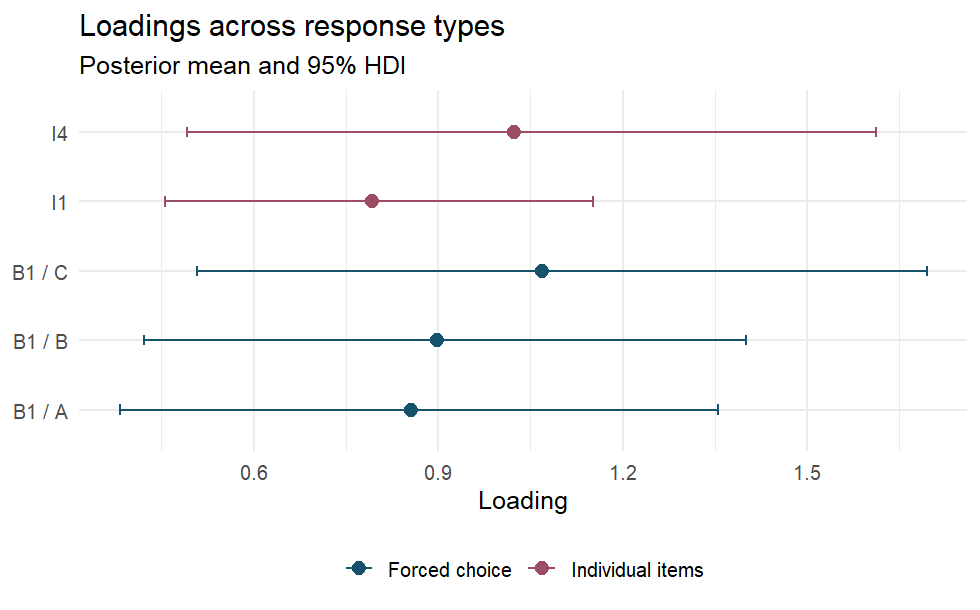

In [8]:
loadings$label <- c(paste(loadings$unit[loadings$channel == "fc"],
                          unlist(loadings$statement[loadings$channel == "fc"]), sep = " / "),
                    loadings$unit[loadings$channel == "items"])

ggplot2::ggplot(loadings, ggplot2::aes(mean, label, color = channel)) +
  ggplot2::geom_errorbar(ggplot2::aes(xmin = hdi95_lb, xmax = hdi95_ub),
                         orientation = "y", width = 0.15) +
  ggplot2::geom_point(size = 3) +
  ggplot2::scale_color_manual(values = c(fc = "#16536b", items = "#9a4d63"),
                              labels = c(fc = "Forced choice", items = "Individual items")) +
  ggplot2::labs(x = "Loading", y = NULL, color = NULL,
                title = "Loadings across response types", subtitle = "Posterior mean and 95% HDI") +
  ggplot2::theme_minimal(base_size = 13) +
  ggplot2::theme(legend.position = "bottom")

## Select a respondent's trait draws

Use the respondent and trait labels with `as_draws()`. The selected samples can
go directly to `posterior` for an R summary. For P001, agency combines the
forced-choice and individual-item responses. Stability uses the forced-choice
responses.

In [9]:
draws <- as_draws(m, variables = "theta",
                  coords = list(person = "P001", trait = c("agency", "stability")))
scores <- posterior::summarise_draws(draws, "mean", "sd", "rhat")
scores$trait <- attr(draws, "coordinates")$theta$trait
scores[c("trait", "mean", "sd", "rhat")]

# A tibble: 2 x 4
  trait       mean    sd  rhat
  <chr>      <dbl> <dbl> <dbl>
1 agency    -0.365 0.373 1.000
2 stability -0.871 0.584 1.00 


See the [R API reference](../reference/r_api.md) for group, covariate and
new-respondent options for mixed tests.